In [1]:
%load_ext autoreload
%autoreload 2

In [15]:
from utils import show_img_chw

In [2]:
from datasets import get_dataset
import matplotlib.pyplot as plt
import wandb
from datasets import get_dataset
import torch
from utils import save_run, load_run
from funcs import train_epoch, val_epoch, test_epoch
from transforms import Div255, SplitEqually
from torchvision.transforms.v2 import (
    ScaleJitter,
    RandAugment,
    RandomCrop,
    Compose,
    ColorJitter,
    RandomHorizontalFlip,
    Normalize,
    RandomApply,
    UniformTemporalSubsample,
    CenterCrop,
    Lambda,
)
from weight_inits import init_timesformer
from torch.utils.data import DataLoader
from models.vivit_custom.utils.scheduler import WarmupCosineSchedule

from pytorchvideo.transforms import UniformTemporalSubsample, ApplyTransformToKey
from constants import HMDB_CLASSES, UCF101_CLASSES
from transformers import TimesformerConfig, TimesformerForVideoClassification
from transformers import ViTForImageClassification
from pytorchvideo.transforms import MixUp

C:\Users\Wojtek\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
frames = 8

In [5]:
ds_transform_train = Compose(
   transforms=[
       UniformTemporalSubsample(num_samples=frames, temporal_dim=0),
       # RandomHorizontalFlip(p=0.5),
       # ScaleJitter(target_size=(240, 320), scale_range=(0.9, 1.33)),
       # RandomCrop(size=(224, 224), pad_if_needed=True, fill=128),
       # RandomApply(p=0.8, transforms=[ColorJitter(brightness=0.2, contrast=0.1, saturation=0.1, hue=0.1)]),
       # RandAugment(num_ops=2, magnitude=10, fill=128),
       # Div255(),
       # Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
   ]
)

ds_transform_valid = Compose(
   transforms=[
       UniformTemporalSubsample(num_samples=frames, temporal_dim=0),
       # CenterCrop((224, 224)),
       # Div255(),
       # Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
   ]
)

test_transform = Compose(
   [
       ApplyTransformToKey(
           key="video",
           transform=Compose(
               [
                   Lambda(lambda x: x.type(torch.uint8)),
                   Lambda(lambda x: x.permute(1, 0, 2, 3)),
                   # SplitEqually(num_frames=64),
                   # UniformTemporalSubsample(num_samples=8, temporal_dim=-4),
                   # CenterCrop(size=(224, 224)),
                   # Div255(),
                   # Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
               ]
           ),
       ),
       ApplyTransformToKey(key="label", transform=Compose([lambda x: UCF101_CLASSES.index(x)])),
   ]
)

In [25]:
dataset_train, dataset_valid, dataset_test = get_dataset(
     "ucf101",
     ds_transform_train,
     ds_transform_valid,
     test_transform
)

100%|██████████| 833/833 [01:46<00:00,  7.84it/s]


Typing


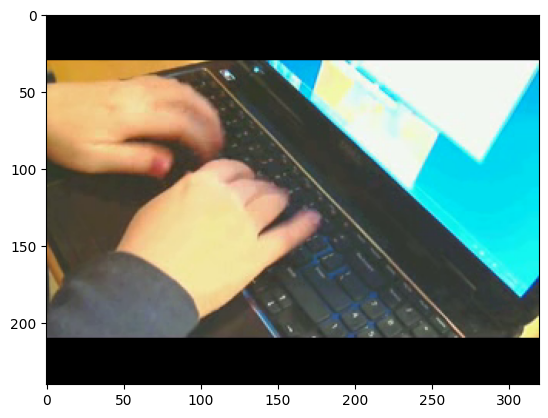

In [69]:
n = 22000
print(UCF101_CLASSES[dataset_train[n][2]])
show_img_chw(dataset_train[n][0][0])